# Capstone Project
# CAP182
# SS3 PART B

# IMPORT REQUIRED LIBRARIES

In [11]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. Load dataset

The STADIOEquities account activation dataset is loaded into a Pandas
DataFrame

In [12]:

import pandas as pd

df = pd.read_csv("C:/Users/ASUS/Downloads/stadioequities_account_activation_extract.csv", sep=",")
# display the first records
print(df.head())

  account_id    registration_date registration_platform   age  \
0  ACC102751  2025-07-14 16:22:24                   App  82.0   
1  ACC100280  2025-02-09 22:32:15                   App  48.0   
2  ACC104223  2025-01-19 09:42:23                   App  34.0   
3  ACC102192  2026-07-20 14:56:50                   Web  52.0   
4  ACC100491  2026-02-20 13:40:12                   App  47.0   

             region   investment_goal risk_appetite acquisition_channel  \
0           Limpopo               NaN          High             Display   
1           Limpopo  Long-term growth           Low            Organic    
2    Western Cape    Long-term growth      Moderate         Paid search   
3      Eastern Cape    Education fund          High               Email   
4           Gauteng  Short-term gains          High        Social media   

     campaign_id  acquisition_cost  ...  first_deposit_made  \
0  CAMP_2025_005            300.54  ...                   0   
1            NaN              9.

In [13]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names and data types
df.info()

# Target variable
target = "first_deposit_made"

print("\nTarget class counts:")
print(df[target].value_counts().sort_index())

print("\nTarget class percentages:")
print(
    (df[target].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

# Missing values
print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).head(20))

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

if "account_id" in df.columns:
    print("Duplicate account IDs:", df["account_id"].duplicated().sum())

Number of rows: 11447
Number of columns: 39
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11447 entries, 0 to 11446
Data columns (total 39 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   account_id                  11447 non-null  object 
 1   registration_date           11447 non-null  object 
 2   registration_platform       11447 non-null  object 
 3   age                         11367 non-null  float64
 4   region                      11447 non-null  object 
 5   investment_goal             11128 non-null  object 
 6   risk_appetite               11447 non-null  object 
 7   acquisition_channel         11447 non-null  object 
 8   campaign_id                 8483 non-null   object 
 9   acquisition_cost            10877 non-null  float64
 10  kyc_started                 11447 non-null  int64  
 11  kyc_completed               11447 non-null  int64  
 12  kyc_completion_time         8957 non-null   

total_deposits_30_days        7546
days_to_first_deposit         7546
first_deposit_amount          7546
support_contact_reason        6828
campaign_id                   2964
kyc_completion_time           2490
acquisition_cost               570
investment_goal                319
first_session_duration         169
screens_viewed                 137
age                             80
marketing_engagement_rate        1
number_of_deposits_30_days       0
email_clicked                    0
withdrawal_made                  0
trading_activity                 0
premium_subscription             0
first_deposit_made               0
account_status                   0
support_tickets                  0
dtype: int64


Duplicate rows: 27
Duplicate account IDs: 27


The dataset provided by the client contains **11,447 instances (rows)** and **39 features (columns)**.  
Each row represents a unique customer account activation record, with attributes such as `account_id`, `registration_date`, `region`, `investment_goal`, `risk_appetite`, `kyc_completed`, `first_deposit_made`, and others.  

- **Classes (Target Variable):**  
  The relevant classification column/target variable is `first_deposit_made`, where 0
represents an account that did not make a first deposit within the
defined activation window and 1 represents an account that did  

- **Class Distribution:**  
  The dataset is imbalanced because the first deposit_made is 3901, while no first deposit_made is 7546

**Imbalance Proportion:**  
  The imbalance proportion is Majority class 65.92 % and Minority class 34.08 % , this is a moderate imbalance . Hence we will apply class weights during model training


# 2: Dataset preprocessing

## Dataset Preparation and explanation for the steps done

The STADIOEquities dataset was prepared to ensure that the data was clean, consistent, and suitable for training a machine learning classification model to predict whether a registered account would make its first deposit within 30 days.

First, records with missing target values were removed because supervised learning requires known outcomes, and the target variable was converted to an integer representing the two classes: 0 (No First Deposit) and 1 (First Deposit). Duplicate account records were removed to prevent repeated observations from distorting the model's learning process. Registration and data extraction dates were converted into numerical calendar features, including year, month, and day of the week, allowing the model to identify potential temporal patterns.

Next, identifiers and variables that could reveal the outcome, such as account IDs, first deposit amounts, deposit counts, and days to first deposit, were excluded to reduce target leakage and ensure that predictions relied on relevant information available before activation. Columns containing only missing values were also removed because they provide no useful information. The remaining features were separated into numerical and categorical variables to support appropriate preprocessing, such as imputation and encoding.

The dataset was then divided into three subsets using Scikit-learn's `train_test_split` function and a fixed random state of 42 to ensure reproducibility. The first split allocated 60% of the data to training and 40% to a temporary dataset, which was subsequently divided equally into 20% validation and 20% testing data. Stratified sampling was applied to preserve approximately the same proportions of activated and non-activated accounts across all three subsets.

Finally, the number of records and class proportions in each subset were printed to verify the split and assess potential class imbalance. The training set is used to fit the model, the validation set supports model selection and parameter tuning, and the test set provides an independent evaluation of performance on unseen data. Overall, this preparation improves data quality, reduces leakage risks, supports reproducible experiments, and establishes a reliable foundation for predicting first-deposit activation at STADIOEquities.

In [14]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# Remove records with a missing target
df = df.dropna(subset=[target]).copy()
df[target] = df[target].astype(int)

# Remove duplicate account records
if "account_id" in df.columns:
    df = df.drop_duplicates(
        subset=["account_id"], keep="first"
    ).copy()
else:
    df = df.drop_duplicates().copy()

# Convert dates into numerical calendar features
for col in ["registration_date", "data_extraction_date"]:
    if col in df.columns:
        dates = pd.to_datetime(df[col], errors="coerce")

        df[f"{col}_year"] = dates.dt.year
        df[f"{col}_month"] = dates.dt.month
        df[f"{col}_dayofweek"] = dates.dt.dayofweek

        df.drop(columns=[col], inplace=True)

# Exclude identifiers and variables that could reveal the outcome
excluded_columns = [
    "account_id",
    target,
    "days_to_first_deposit",
    "first_deposit_amount",
    "total_deposits_30_days",
    "number_of_deposits_30_days",
    "withdrawal_made",
    "trading_activity",
    "premium_subscription",
    "account_status"
]

X = df.drop(
    columns=[c for c in excluded_columns if c in df.columns]
)

y = df[target]

# Remove columns that contain no usable values
empty_columns = X.columns[X.isna().all()].tolist()
X = X.drop(columns=empty_columns)

print("Features available:", X.shape[1])
print("Target records:", len(y))

# Identify numerical and categorical variables
numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# First split: 60% training, 40% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=RANDOM_STATE,
    stratify=y
)

# Second split: 20% validation, 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("\nTraining records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nValidation class proportions:")
print(y_val.value_counts(normalize=True).sort_index().round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Features available: 33
Target records: 11420
Numerical features: ['age', 'acquisition_cost', 'kyc_started', 'kyc_completed', 'kyc_completion_time', 'onboarding_completion', 'onboarding_steps_completed', 'onboarding_steps_abandoned', 'first_session_duration', 'sessions_before_day30', 'login_frequency', 'screens_viewed', 'investment_features_used', 'product_pages_viewed', 'email_opened', 'email_clicked', 'nudge_received', 'nudge_engagement', 'marketing_engagement_rate', 'support_tickets', 'registration_date_year', 'registration_date_month', 'registration_date_dayofweek', 'data_extraction_date_year', 'data_extraction_date_month', 'data_extraction_date_dayofweek']
Categorical features: ['registration_platform', 'region', 'investment_goal', 'risk_appetite', 'acquisition_channel', 'campaign_id', 'support_contact_reason']

Training records: 6852
Validation records: 2284
Testing records: 2284

Training class proportions:
first_deposit_made
0    0.659
1    0.341
Name: proportion, dtype: float64

## build the preprocessing pipeline

The preprocessing stage used Scikit-learn's `Pipeline` and `ColumnTransformer` to prepare numerical and categorical features for the STADIOEquities first-deposit activation prediction model. For numerical features, missing values were replaced with the median using `SimpleImputer(strategy="median")`, and `StandardScaler()` was applied to standardise the features. For categorical features, missing values were replaced with the most frequent category using `SimpleImputer(strategy="most_frequent")`, while `OneHotEncoder(handle_unknown="ignore")` converted categories into numerical representations and handled previously unseen categories without errors. The `ColumnTransformer` combined both pipelines to ensure that each feature type received the appropriate transformations. Overall, this approach improves data consistency, handles missing values, and prepares the dataset for machine learning. The preprocessing pipeline should be fitted on the training data only and then applied to the validation and test datasets to prevent data leakage and support reliable model evaluation.

In [15]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 3: Model training


Gradient Boosting is selected as the final classification method
from SS2. It builds an ensemble of decision trees sequentially,
with each new tree attempting to correct errors made by previous
trees. It can identify nonlinear relationships and interactions
between customer characteristics and engagement variables.

The model uses 200 estimators to provide sufficient boosting
iterations, a learning rate of 0.05 to make gradual updates,
a maximum tree depth of 2 to limit model complexity, and a minimum
leaf size of 10 to reduce overfitting. A subsample of 0.8 adds
regularisation by training each boosting stage on a random subset
of the training data.

The random state is fixed at 42 to support reproducibility.
Preprocessing is included in the model pipeline to ensure that
imputation, scaling and encoding are fitted using training data
only.

## Train gradient Boosting

In [16]:
# Calculate class weights for the training data
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Create the complete model pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=10,
        subsample=0.8,
        random_state=RANDOM_STATE
    ))
])

# Fit the model with sample weights
model.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights
)

print("Gradient Boosting model trained successfully with class weights.")


Gradient Boosting model trained successfully with class weights.


## 4: Model validation

The trained model is evaluated using the validation set during
development and the held-out test set for final evaluation.

Accuracy measures overall correctness. Precision measures the
proportion of predicted activations that are actual activations.
Recall measures the proportion of actual activations correctly
identified. The F1-score balances precision and recall.

ROC-AUC measures the model's ability to rank positive cases above
negative cases, while average precision summarises precision-recall
performance across thresholds. These metrics provide a more
complete assessment than accuracy alone.

The test set is not used to fit the model. It is reserved for
estimating performance on unseen accounts.

# calculate evaluation metrics

In [18]:
from sklearn.metrics import average_precision_score
def evaluate_model(model, X_data, y_data, dataset_name):

    predictions = model.predict(X_data)
    probabilities = model.predict_proba(X_data)[:, 1]

    results = {
        "Dataset": dataset_name,
        "Accuracy": accuracy_score(y_data, predictions),
        "Precision": precision_score(
            y_data, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_data, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_data, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_data, probabilities),
        "Average Precision": average_precision_score(
            y_data, probabilities
        )
    }

    return results


# Evaluate training and validation performance
train_results = evaluate_model(
    model, X_train, y_train, "Training"
)

val_results = evaluate_model(
    model, X_val, y_val, "Validation"
)

# Evaluate the final unseen test set
test_results = evaluate_model(
    model, X_test, y_test, "Unseen Test"
)

results_df = pd.DataFrame([
    train_results,
    val_results,
    test_results
])

display(results_df.round(4))

,Dataset,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Training,0.6604,0.5011,0.8013,0.6166,0.7716,0.6103
1,Validation,0.6362,0.4789,0.7574,0.5868,0.7357,0.5571
2,Unseen Test,0.6502,0.4914,0.7686,0.5995,0.7423,0.5703


# classification report and confusion matrix

Classification Report — Unseen Test Data
                  precision    recall  f1-score   support

No First Deposit       0.83      0.59      0.69      1506
   First Deposit       0.49      0.77      0.60       778

        accuracy                           0.65      2284
       macro avg       0.66      0.68      0.64      2284
    weighted avg       0.72      0.65      0.66      2284

Confusion Matrix:
[[887 619]
 [180 598]]


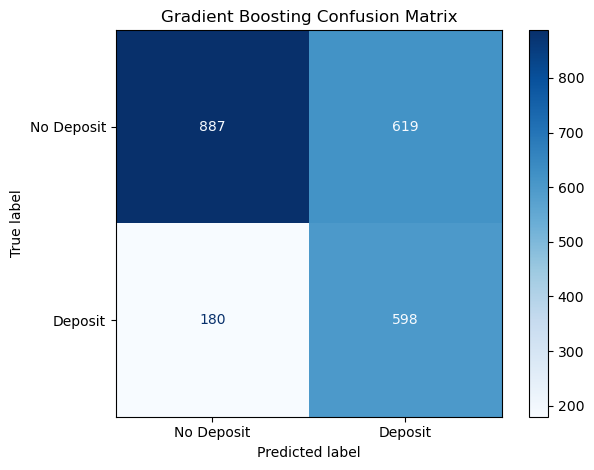

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predictions for unseen test data
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Classification Report — Unseen Test Data")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=[
        "No First Deposit",
        "First Deposit"
    ],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Deposit", "Deposit"]
).plot(cmap="Blues", values_format="d")

plt.title("Gradient Boosting Confusion Matrix")
plt.tight_layout()
plt.show()

# 5: Results visualisation

Visualisations are used to compare training, validation and unseen
test performance. The metric comparison graph helps identify
possible overfitting. The confusion matrix illustrates correct
and incorrect classifications, while the ROC and precision-recall
curves show how model performance changes across classification
thresholds.

Feature importance is also examined to identify which predictors
contribute most to the fitted Gradient Boosting model. These
importance scores indicate predictive contribution, not causation.

# 5.1 Training versus validation and test performance

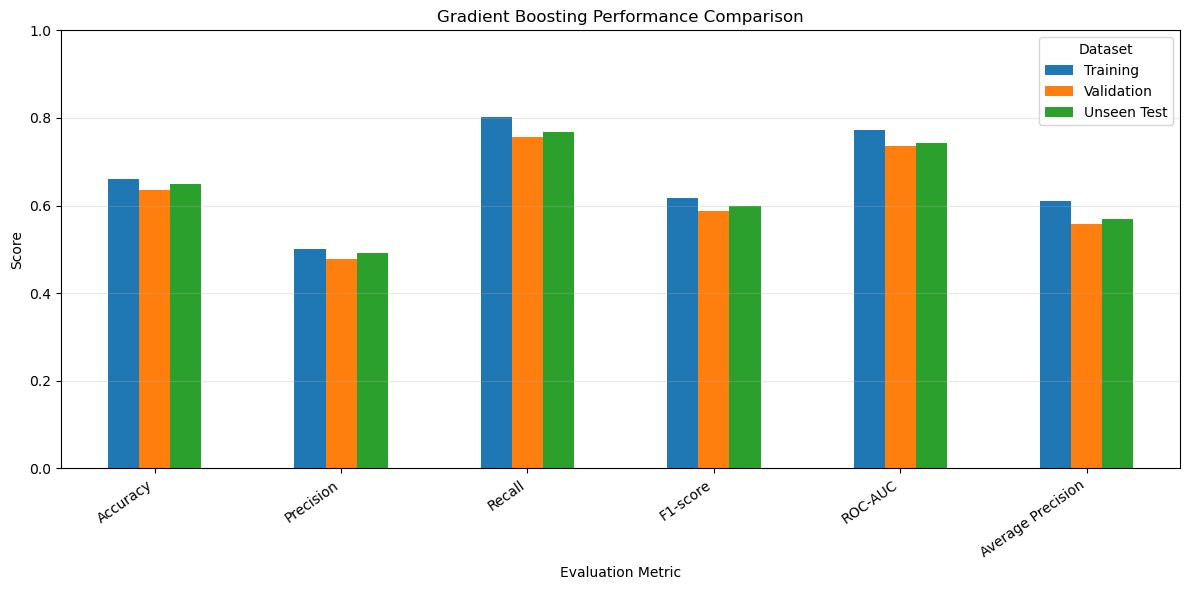

In [20]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "Average Precision"
]

plot_data = results_df.set_index("Dataset")[metrics_to_plot]

ax = plot_data.T.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Gradient Boosting Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Evaluation Metric")
ax.set_ylim(0, 1)
ax.legend(title="Dataset")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# 5.2 ROC curve

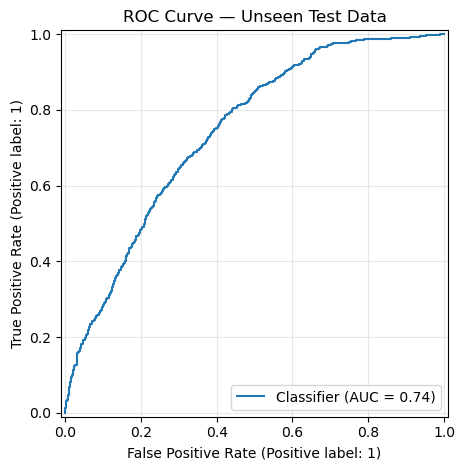

In [21]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("ROC Curve — Unseen Test Data")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 5.3 Precision-recall curve

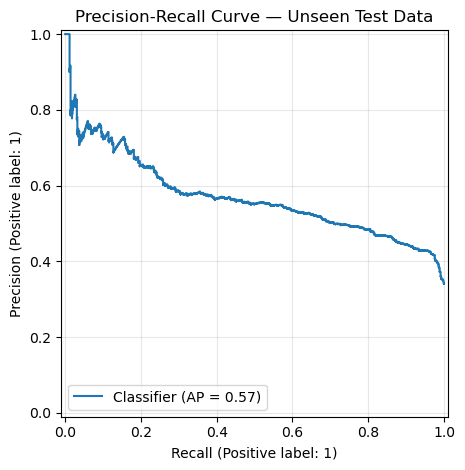

In [22]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("Precision-Recall Curve — Unseen Test Data")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6.4 Feature importance

,Feature,Importance
3,numeric__kyc_completed,0.441664
5,numeric__onboarding_completion,0.182242
1,numeric__acquisition_cost,0.064529
17,numeric__nudge_engagement,0.055434
9,numeric__sessions_before_day30,0.034946
10,numeric__login_frequency,0.024232
11,numeric__screens_viewed,0.019305
18,numeric__marketing_engagement_rate,0.015996
0,numeric__age,0.015456
34,categorical__registration_platform_Web,0.013756


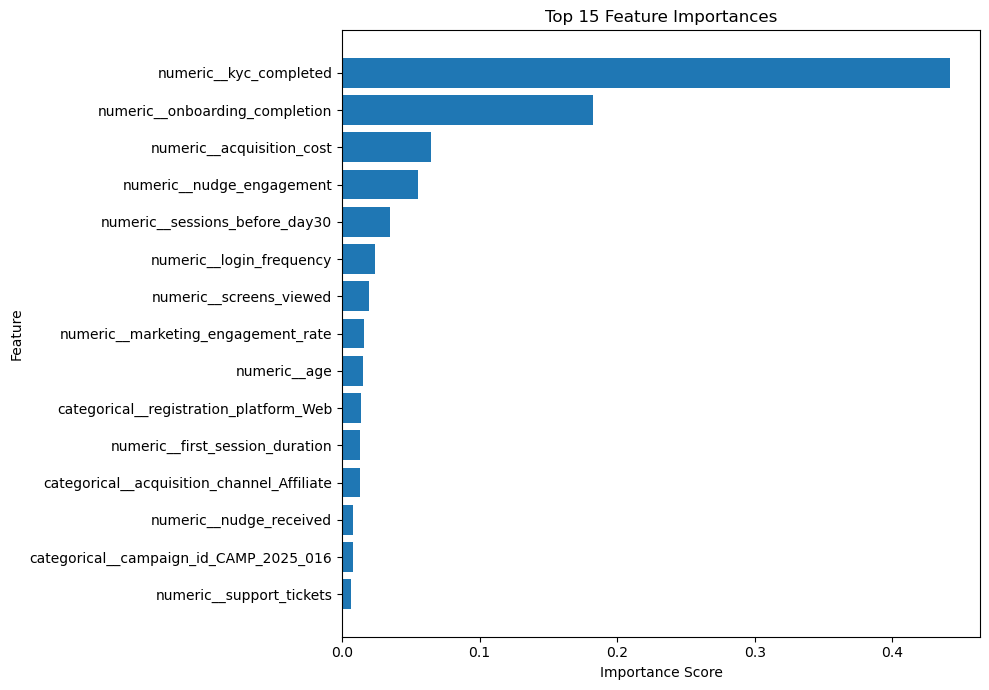

In [23]:
# Retrieve the fitted preprocessing and classification steps
fitted_preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

# Recover feature names after encoding
feature_names = fitted_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": classifier.feature_importances_
})

# Display the 15 most important features
top_features = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

display(top_features)

# Plot feature importance
top_features = top_features.sort_values("Importance")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()